In [1]:
%load_ext autoreload
%autoreload 2
%load_ext jupyter_black

import sys
from pathlib import Path

scripts_path = str(Path.cwd().parents[1]) + "/scripts/"
if scripts_path not in sys.path:
    sys.path.insert(0, scripts_path)

from Config import MPLSTYLE

import Syn_Spec_toolkit as SSt
import plot_toolkit as PLOT

import numpy as np
import matplotlib.pyplot as plt, matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import astropy.units as u
import astropy.constants as const
from astropy.config import generate_config

generate_config(pkgname="synphot")

from sedfitter.sed import SEDCube
from synphot.models import Empirical1D
from synphot import units, SourceSpectrum
from astroquery.svo_fps import SvoFps

import matplotlib.colors as mcolors
import matplotlib.cm as cm
from tqdm import tqdm

if MPLSTYLE.exists():
    plt.style.use(str(MPLSTYLE))

/net/vdesk/data2/slagter/environment_path/NGC_env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
Tspace = np.arange(4000, 10000, 500)
Tspace_all = np.arange(1000, 20000, 500)
filters_pa = ["F187N", "F115W", "F200W"]
filters_br = ["F405N", "F115W", "F200W"]

#### Pa-$\alpha$

In [3]:
MAGS_per_filter = SSt.Compute_delta_m_no_lines_over_model(
    filters=filters_pa, Tspace=Tspace
)

fitted_func, slope, intercept = SSt.Fit_CC_relation(
    x=MAGS_per_filter[1] - MAGS_per_filter[2], y=MAGS_per_filter[1] - MAGS_per_filter[0]
)

MAGS_per_filter_all = SSt.Compute_delta_m_no_lines_over_model(
    filters=filters_pa, Tspace=Tspace_all
)

100%|██████████| 38/38 [00:02<00:00, 14.76it/s]


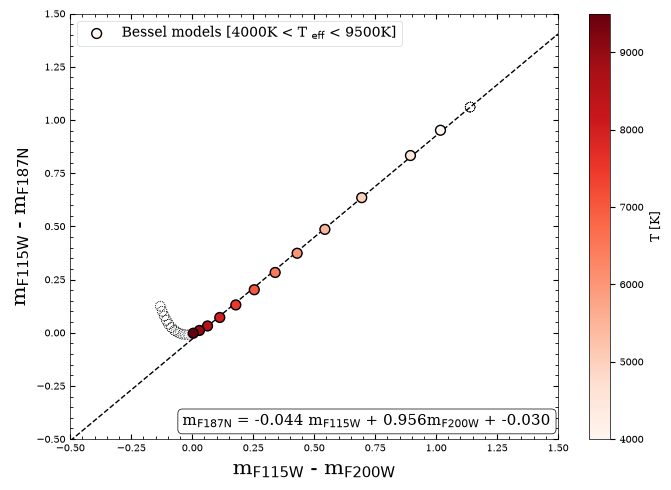

In [4]:
SSt.plot_CC_relation_bessel(
    Tspace=Tspace,
    Tspace_all=Tspace_all,
    filters=filters_pa,
    MAGS_per_filter=MAGS_per_filter,
    MAGS_per_filter_all=MAGS_per_filter_all,
    fitted_func=fitted_func,
    slope=slope,
    intercept=intercept,
    xlim=(-0.5, 1.5),
    ylim=(-0.5, 1.5),
)

#### Br-$\alpha$

In [5]:
MAGS_per_filter = SSt.Compute_delta_m_no_lines_over_model(
    filters=filters_br, Tspace=Tspace
)

fitted_func, slope, intercept = SSt.Fit_CC_relation(
    x=MAGS_per_filter[1] - MAGS_per_filter[2], y=MAGS_per_filter[1] - MAGS_per_filter[0]
)

MAGS_per_filter_all = SSt.Compute_delta_m_no_lines_over_model(
    filters=filters_br, Tspace=Tspace_all
)

100%|██████████| 38/38 [00:02<00:00, 16.00it/s]


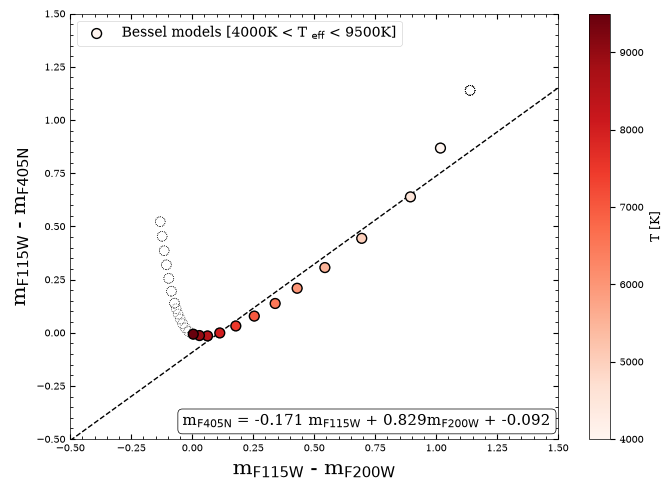

In [6]:
SSt.plot_CC_relation_bessel(
    Tspace=Tspace,
    Tspace_all=Tspace_all,
    filters=filters_br,
    MAGS_per_filter=MAGS_per_filter,
    MAGS_per_filter_all=MAGS_per_filter_all,
    fitted_func=fitted_func,
    slope=slope,
    intercept=intercept,
    xlim=(-0.5, 1.5),
    ylim=(-0.5, 1.5),
)

In [7]:
Tspace = np.arange(4000, 10000, 500)
Tspace_all = np.arange(1000, 20000, 500)

filters_pa = ["F187N", "F115W", "F200W", "F277W", "F335M", "F444W"]

filters_pa = ["F405N", "F115W", "F200W", "F277W", "F335M", "F444W"]

MAGS_per_filter = SSt.Compute_delta_m_no_lines_over_model(
    filters=filters_pa, Tspace=Tspace
)

MAGS_per_filter_all = SSt.Compute_delta_m_no_lines_over_model(
    filters=filters_pa, Tspace=Tspace_all
)

100%|██████████| 38/38 [00:04<00:00,  9.19it/s]


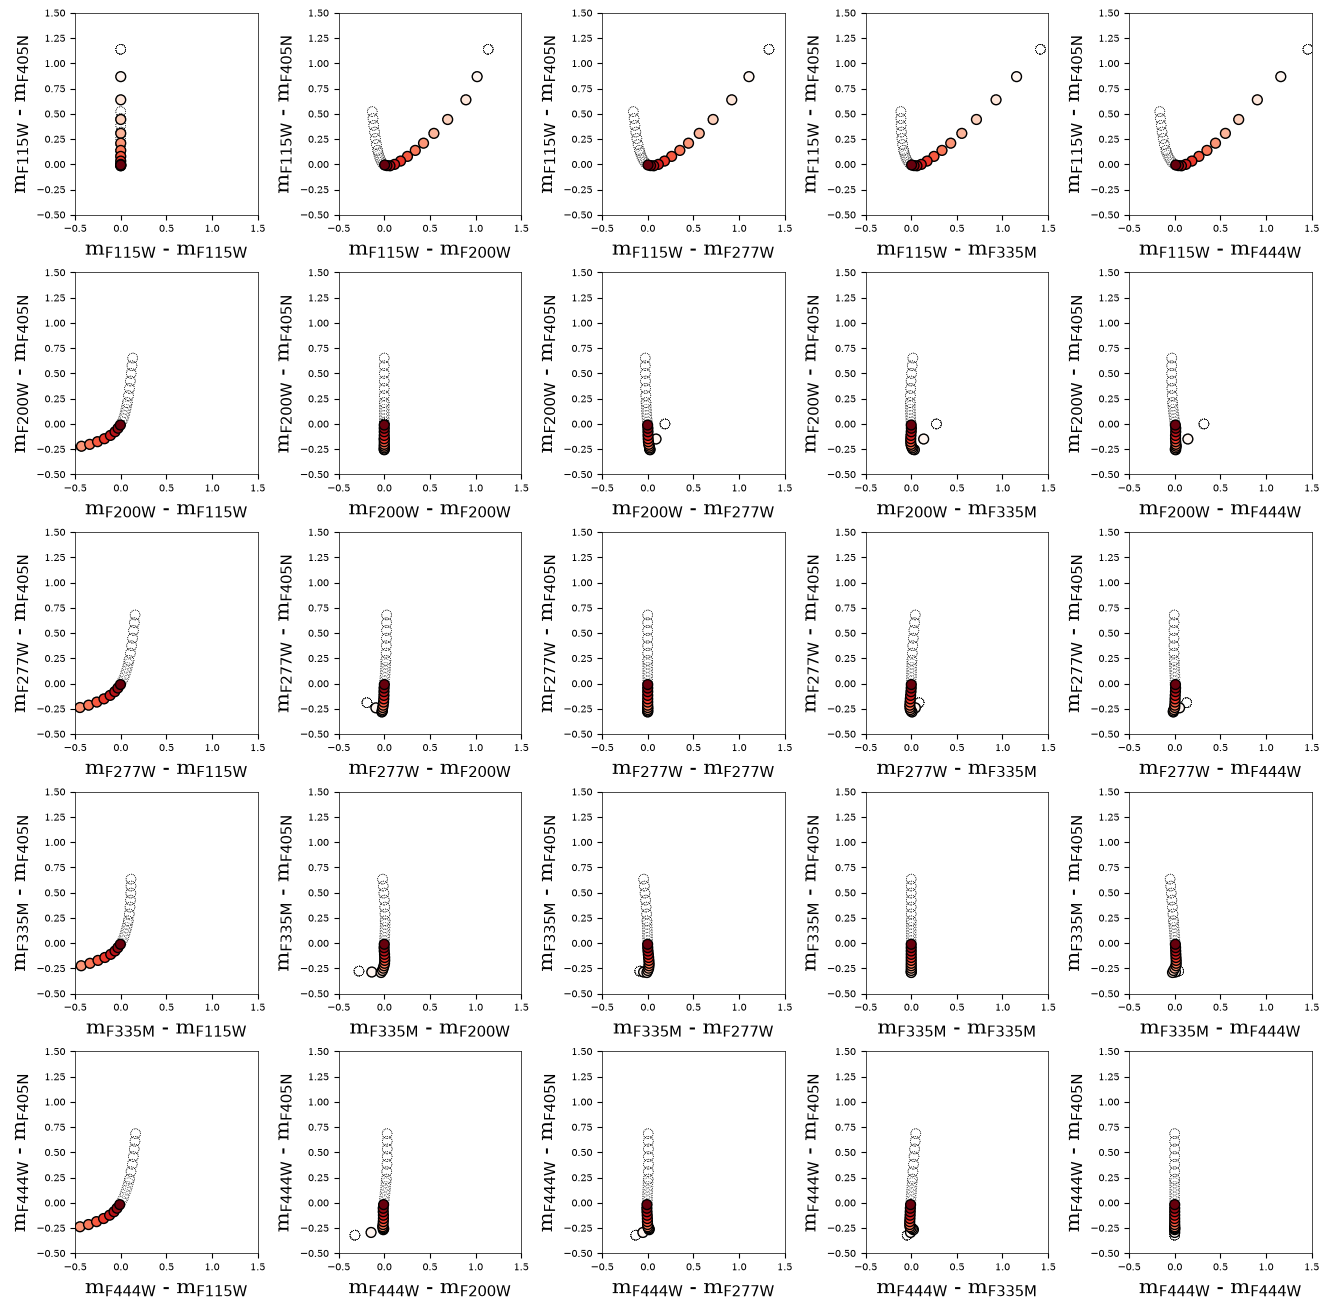

In [8]:
import itertools
import matplotlib.pyplot as plt

n_filters = 6
filter_indices = list(range(n_filters))

combinaties = list(itertools.combinations(filter_indices, 2))
fig, axes = plt.subplots(6, 6, figsize=(15, 15), constrained_layout=True)


xmin, xmax = -0.5, 1.5
ymin, ymax = -0.5, 1.5

# Loop door alle subplots om de bovenste driehoek te verbergen
for i in range(6):
    for j in range(6):
        if i == 0 or j == 0:
            axes[i, j].remove()  # axis("off")
        else:
            ax = axes[i, j]

            all_bessel = ax.scatter(
                MAGS_per_filter_all[i, :] - MAGS_per_filter_all[j, :],
                MAGS_per_filter_all[i, :] - MAGS_per_filter_all[0, :],
                c="none",
                edgecolor="k",
                ls=":",
                s=50,
                zorder=2,
            )

            scatters = ax.scatter(
                MAGS_per_filter[i, :] - MAGS_per_filter[j, :],
                MAGS_per_filter[i, :] - MAGS_per_filter[0, :],
                c=Tspace,
                cmap="Reds",
                edgecolor="k",
                lw=1,
                label=rf"Bessel models [{Tspace.min()}K < T $_{{\mathrm{{eff}}}}$ < {Tspace.max()}K]",
                s=50,
                zorder=2,
            )
            ax.set_xlabel(
                f"{PLOT._make_mag_name(filters_pa[i])} - {PLOT._make_mag_name(filters_pa[j])}",
                fontsize=15,
            )
            ax.set_ylabel(
                f"{PLOT._make_mag_name(filters_pa[i])} - {PLOT._make_mag_name(filters_pa[0])}",
                fontsize=15,
            )
            ax.set_xlim(xmin, xmax)
            ax.set_ylim(ymin, ymax)


plt.show()